# Analyzing your sensor and survey data from the CBA CAB Lab

This notebook walks through a basic analysis of the iMotions sensor data and Qualtrics survey data delivered by the lab. Run the cells from top to bottom (select a cell and press **Shift + Enter**). Only the cells in the **Settings** section normally need to be edited.

Steps:

1. Load the data
2. Build one dataset that combines survey answers and sensor measures
3. Plot the distribution of two variables (KDE plot)
4. Run an OLS regression
5. Run a SurvivalScale analysis for Likert (agree/disagree) questions
6. Explore what else CBACABLab can do with your data

Your folder from the lab should contain `Survey.xlsx`, `Survey.csv` and the `sensorData` folder along with this notebook.

In [120]:
# Run this cell once to install the required packages. Remove the leading # on the next line first.
# %pip install CBACABLab SurvivalScale statsmodels

In [121]:
from pprint import pprint
import pandas as pd
from pathlib import Path
import sys

for project_root in (Path.cwd(), *Path.cwd().parents):
    src_dir = project_root / "src"
    if (src_dir / "CBACABLab").is_dir():
        sys.path.insert(0, str(src_dir))
        break

## Settings

Change these to match your study. The question names (like `Q1`) are the question names from your Qualtrics survey.

In [122]:
import CBACABLab

# The settings for the database, survey, sensor folder should not have to be changed if you kept the folder structure
# sent to you by the lab.  If you changed the folder structure, you will need to change these settings to match your study.

DATABASE = "data.db"          # file created to store your data
SURVEY_FILE = "Survey.xlsx"   # the Excel version of the survey from Qualtrics
SURVEY_CSV_FILE = "Survey.csv" # the CSV version of the survey from Qualtrics
SENSOR_FOLDER = "./sensorData/" # Where iMotions sensor data is stored.

# Autodetects and matches survey question ids (QIDs) to the question names. 
question_mapping = CBACABLab.AutoDetermineQuestionIdtoQuestionNameMapping(surveyName=SURVEY_FILE, surveyCSVName=SURVEY_CSV_FILE)

# Questions at the respondent level (e.g. demographics, fact based, etc.) that should not be connected
# to instument/sensor data.
RESPONDENT_QUESTIONS = ["Q4_4", "Q5_4", "Q6", "Q7"]

# Example of Likert questions (e.g. Strongly disagree ... Strongly agree) and the number each answer maps to. 
# We also have built-in support for cerain Likert scales.  We will show this later in the notebook. 
# For now, you can define your own scales as shown below.

AGREEMENT_SCALE = {
    "Strongly disagree": 0,
    "Somewhat disagree": 1,
    "Neither agree nor disagree": 2,
    "Somewhat agree": 3,
    "Strongly agree": 4,
}

LIKERT_SCALES = {question: AGREEMENT_SCALE for question in ["Q1", "Q2", "Q3"]}

# Screen regions (tags) shown to participants, and the sensor measures to include.  Note that these are not necessary
# but might be useful for your analysis if you want to look at how people interact with specific areas of the screen. 
# You can ignore tags entirely if you don't need them.

TAGS = ["left", "right"]

# These are the instrument measures beyond pupil and gaze duration that you want to include in your analysis. The choice of
# Attention and Joy is arbitrary.  The example dataset has 47 different instument properties.  You can include as many 
# or as few as you want.  

INSTRUMENT_PROPERTIES = ["Attention", "Joy"]



## 1. Load the data

This reads the survey and sensor files into a local database (`data.db`). It can take a few minutes. Each region of the screen is loaded as a set of bounding boxes `(left, right, top, bottom)` (both have only one bounded box but more are supported for each tag) in pixels with its own tag.  This isn't necessary for all analyses, but it allows you to analyze the data by region of the screen; the example below corresponds to someone analyzing instrument data when the participant is looking at the right side of the screen or the left side of the screen.  If you don't need this, you can set `boundingBoxes = None` in the `LoadSensorData` call below.  You would also only need to load the sensor data once, and then you can reuse the database for future analyses.



In [123]:

# Loads the Qualtrics survey data into the database.  This is a one-time operation.  
# If you have already loaded the survey data, you can skip this step.
CBACABLab.LoadSurveyData(databaseName=DATABASE, surveyName=SURVEY_FILE)

# Left half of a 1920x1080 screen. rebuild=True clears old sensor data first.
CBACABLab.LoadSensorData(
   databaseName=DATABASE,
    sensorFolder=SENSOR_FOLDER,
    boundedboxes=[(0, 960, 0, 1080)],
    tag="left",
    rebuild=True,
    questionIdtoQuestionName=question_mapping,
)

# This loads the right half of the screen.  This is how multiple tags can be created.
CBACABLab.LoadSensorData(
    databaseName=DATABASE,
    sensorFolder=SENSOR_FOLDER,
    boundedboxes=[(960, 1920, 0, 1080)],
    tag="right",
    questionIdtoQuestionName=question_mapping,
)

# See which survey questions are available
CBACABLab.ListQuestions(DATABASE)

['Last Seen Flow Element ID',
 'Q1',
 'Q2',
 'Q3',
 'Q4_4',
 'Q5_4',
 'Q6',
 'Q7',
 'iMotionsRespondent',
 'iMotionsStudy']

## 2. Build the analysis dataset

This combines the survey answers and sensor measures into one table, with one row for each person and Likert question (or more generally, questions you want on their own rows).

Note that even at this stage, you could simply export the `panel` table to a CSV file and do your analysis in another tool (`panel.to_csv('panel.csv')`).  But CBACABLab has built-in support for many common analyses, and Python is an ideal language for data analysis.

In [124]:
panel = CBACABLab.CreatePanelData(
    question_level_columns=["Q1", "Q2", "Q3"],
    respondent_level_columns=RESPONDENT_QUESTIONS,
    tagFilter=TAGS,
    instrumentProperties=INSTRUMENT_PROPERTIES,
    databaseName=DATABASE,
)
panel.head(10)

,respondent_id,question,response,duration_left,duration_right,pupil_left,pupil_right,Attention_left,Attention_right,Joy_left,Joy_right,Q4_4,Q5_4,Q6,Q7
0,1,Q1,Strongly disagree,343.472949,357.075008,2.628579,2.714873,98.137547,97.839279,0.034117,0.037362,65.198,22.066,Other,Bachelor's Degree
1,1,Q2,Neither agree nor disagree,358.868249,1916.269888,2.776471,2.833336,97.348034,98.041817,0.120167,1.596050,65.198,22.066,Other,Bachelor's Degree
2,1,Q3,Strongly agree,409.204696,694.727733,2.817981,2.836787,NaN,97.550504,NaN,0.052147,65.198,22.066,Other,Bachelor's Degree
3,2,Q1,Strongly agree,384.045313,722.940208,2.693345,2.841391,97.755627,97.696284,0.025384,0.025649,89.207,94.341,White/ Caucasian,Prefer not to say
4,2,Q2,Neither agree nor disagree,1027.143104,398.548022,2.739849,2.741312,95.377090,97.866264,0.025275,0.024139,89.207,94.341,White/ Caucasian,Prefer not to say
5,2,Q3,Somewhat disagree,736.664201,NaN,2.752320,NaN,97.902746,NaN,25.002819,NaN,89.207,94.341,White/ Caucasian,Prefer not to say
6,3,Q1,Neither agree nor disagree,380.960150,264.400428,2.719926,2.847198,98.039979,98.498688,26.620419,0.036503,100.000,2.458,White/ Caucasian,High school diploma / GED
7,3,Q2,Strongly disagree,591.957592,438.112677,2.702798,2.532557,97.798824,98.661983,90.557137,0.024104,100.000,2.458,White/ Caucasian,High school diploma / GED
8,3,Q3,Somewhat disagree,733.998717,257.911149,2.662162,2.658208,97.131732,98.370094,0.029900,0.038205,100.000,2.458,White/ Caucasian,High school diploma / GED
9,4,Q1,Somewhat agree,385.729328,402.003738,2.624093,2.658857,97.832081,NaN,0.043469,NaN,51.432,7.629,Asian/ Asian American,Master's Degree


After creating the `panel` table, you might want to see all the available columns.  You can do this with `panel.columns`.

In [125]:
list(panel.columns)

['respondent_id',
 'question',
 'response',
 'duration_left',
 'duration_right',
 'pupil_left',
 'pupil_right',
 'Attention_left',
 'Attention_right',
 'Joy_left',
 'Joy_right',
 'Q4_4',
 'Q5_4',
 'Q6',
 'Q7']

## 3. Plot two variables (KDE plot)

A KDE plot is a smooth version of a histogram that shows how a variable's values are spread out. Here we compare the pupil measure for the left and right regions. Replace the column names with any numeric columns listed above.

Silverman Bandwidths:  [np.float64(0.03890326185145091), np.float64(0.05434455866124752)]


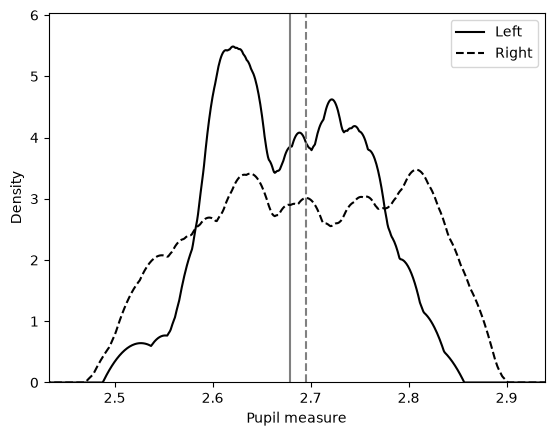

In [126]:

series = [panel[column].dropna() for column in ["pupil_left", "pupil_right"]]

CBACABLab.ProjectKDEPlot(
    series,
    label="Pupil measure",
    labels=["Left", "Right"],
    mean=True,   # draw a line at each average
)

## 4. OLS regression

OLS (ordinary least squares) is used when the outcome is a number, such as a slider answer or a sensor measure. Here the outcome is `pupil_left`, explained by which question was asked. Because each person answers several questions, the standard errors are clustered by person.

In [127]:
import statsmodels.formula.api as smf

# Formula: outcome ~ explanatory variables. C(question) treats each question as a category.
ols_model = smf.ols("pupil_left ~ C(question)", data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["respondent_id"]}
)
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:             pupil_left   R-squared:                       0.113
Model:                            OLS   Adj. R-squared:                  0.047
Method:                 Least Squares   F-statistic:                     1.619
Date:                Thu, 05 Nov 2026   Prob (F-statistic):              0.251
Time:                        05:59:46   Log-Likelihood:                 38.452
No. Observations:                  30   AIC:                            -70.90
Df Residuals:                      27   BIC:                            -66.70
Df Model:                           2                                         
Covariance Type:              cluster                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             2.6455      0.02

## 5. SurvivalScale for Likert responses

Likert answers are ordered categories, so OLS isn't ideal for them. [SurvivalScale](https://github.com/tazzben/Likert-estimation) estimates how the variables in `FEATURES` affect the Likert response, using the `k` and `bound` columns prepared above. The bootstrap repeats the estimate many times to calculate confidence intervals; increase `bootstrap_iterations` (for example to 1000) for final results, at the cost of a longer run. Sona Klucarova and Ben Smith (and Jadrian Wooten -- but he is at Virginia Tech) developed this method of analysis, so if you have questions about it, please reach out to them.

In [128]:

# Add Likert columns to the panel data. This will add a column for each question with the numeric value of the response (e.g. 0-4 for a 5-point scale). The original response column is kept as well.
panel_likert = CBACABLab.AddLikertColumns(panel, LIKERT_SCALES).reset_index(drop=True)

# The columns the analyses need: id, block (who to cluster by), question, the variable(s) of interest, k and bound
FEATURES = ["pupil_left"]
analysis_data = pd.DataFrame({
    "id": panel_likert["respondent_id"],
    "block": panel_likert["respondent_id"],
    "question": panel_likert["question"],
    "pupil_left": panel_likert["pupil_left"],
    "k": pd.to_numeric(panel_likert["k"], errors="coerce"),
    "bound": pd.to_numeric(panel_likert["bound"], errors="coerce"),
}).dropna()
analysis_data.head(10)

,id,block,question,pupil_left,k,bound
0,1,1,Q1,2.628579,0,4
1,1,1,Q2,2.776471,2,4
2,1,1,Q3,2.817981,4,4
3,2,2,Q1,2.693345,4,4
4,2,2,Q2,2.739849,2,4
5,2,2,Q3,2.752320,1,4
6,3,3,Q1,2.719926,2,4
7,3,3,Q2,2.702798,0,4
8,3,3,Q3,2.662162,1,4
9,4,4,Q1,2.624093,3,4


In [129]:
from SurvivalScale import get_results

cj, beta, metrics = get_results(
    analysis_data,
    bootstrap_iterations=100,
    alpha=0.05,          # 95% confidence intervals
    columns=FEATURES,
    block_id="block",
)
display(beta)     # effect of each variable in FEATURES
display(metrics)  # overall model fit

Performing bootstrap analysis to estimate confidence intervals and p-values...


100%|██████████| 100/100 [00:04<00:00, 20.51it/s]


,beta,marginal,marginal_discrete,lower_bound,upper_bound,p_value
pupil_left,-0.392776,-0.075341,-0.096951,-0.559121,-0.189032,0.0


,Value
McFadden_R2,-0.000309
log_likelihood,-45.777818
restricted_log_likelihood,-45.763662
LR,-0.028312
num_rows,30.000000
Chi-Squared_p-value,NaN
AIC,99.555635
BIC,105.160425


## 6. Explore other things the CBACABLab package can do

The examples below are short and independent. They reuse the settings and the `panel` table created above, so run the earlier cells first.

### 6.1 Summary statistics

`SummaryStatisticsOfCounts` shows counts (and the percent) for categorical columns. `SummaryStatisticsOfContinuous` shows the count, mean, standard deviation, min, quartiles and max for numeric columns. Add `save="results"` to also write each table to a CSV file.

In [130]:
CBACABLab.SummaryStatisticsOfCounts(panel, columns=["response"])
CBACABLab.SummaryStatisticsOfContinuous(panel, columns=["pupil_left", "pupil_right"])

,Count,Percent
Category,,
Strongly agree,10,33.3%
Neither agree nor disagree,7,23.3%
Strongly disagree,5,16.7%
Somewhat disagree,5,16.7%
Somewhat agree,3,10.0%


,pupil_left
count,30.00
mean,2.68
std,0.07
min,2.53
25%,2.62
50%,2.68
75%,2.74
max,2.82


,pupil_right
count,29.00
mean,2.70
std,0.10
min,2.52
25%,2.61
50%,2.71
75%,2.79
max,2.85


### 6.2 Load survey answers only

`LoadQuestionsWide` returns one row per respondent and one column per question you ask for. Use it when you only need survey answers (for example demographics) and no sensor data.

In [131]:
survey_wide = CBACABLab.LoadQuestionsWide(questions=RESPONDENT_QUESTIONS, databaseName=DATABASE)
survey_wide.head()

,respondent_id,Q4_4,Q5_4,Q6,Q7
0,1,65.198,22.066,Other,Bachelor's Degree
1,2,89.207,94.341,White/ Caucasian,Prefer not to say
2,3,100.000,2.458,White/ Caucasian,High school diploma / GED
3,4,51.432,7.629,Asian/ Asian American,Master's Degree
4,5,18.943,80.931,White/ Caucasian,Master's Degree


### 6.3 Load survey answers together with sensor data

These join the survey answers to the sensor data. Both take the questions you want and, optionally, the screen regions (`tagFilter`) and instrument measures (`instrumentProperties`).

* `LoadSurveyWithSensorDataWide`: one row per person and question, with a column for each tag and measure (for example `pupil_left`, `Joy_right` -- left and right are referencing the names of the tags).
* `LoadSurveyWithSensorDataLong`: one row per person, question, tag and measure, with the measure name in `property` and its number in `value`.

In [132]:
sensor_wide = CBACABLab.LoadSurveyWithSensorDataWide(
    questions=["Q1", "Q2", "Q3"],
    databaseName=DATABASE,
    tagFilter=TAGS,
    instrumentProperties=INSTRUMENT_PROPERTIES,
)
sensor_wide.head()

,respondent_id,question,response,duration_left,duration_right,pupil_left,pupil_right,Attention_left,Attention_right,Joy_left,Joy_right
0,1,Q1,Strongly disagree,343.472949,357.075008,2.628579,2.714873,98.137547,97.839279,0.034117,0.037362
1,1,Q2,Neither agree nor disagree,358.868249,1916.269888,2.776471,2.833336,97.348034,98.041817,0.120167,1.596050
2,1,Q3,Strongly agree,409.204696,694.727733,2.817981,2.836787,NaN,97.550504,NaN,0.052147
3,2,Q1,Strongly agree,384.045313,722.940208,2.693345,2.841391,97.755627,97.696284,0.025384,0.025649
4,2,Q2,Neither agree nor disagree,1027.143104,398.548022,2.739849,2.741312,95.377090,97.866264,0.025275,0.024139


In [133]:
sensor_long = CBACABLab.LoadSurveyWithSensorDataLong(
    questions=["Q1", "Q2", "Q3"],
    databaseName=DATABASE,
    tagFilter=TAGS,
    instrumentProperties=INSTRUMENT_PROPERTIES,
)
sensor_long.head()

,respondent_id,question,response,tag,pupil,duration,property,value
0,1,Q1,Strongly disagree,left,2.628579,343.472949,Joy,0.034117
1,1,Q1,Strongly disagree,left,2.628579,343.472949,Attention,98.137547
2,1,Q1,Strongly disagree,right,2.714873,357.075008,Joy,0.037362
3,1,Q1,Strongly disagree,right,2.714873,357.075008,Attention,97.839279
4,1,Q2,Neither agree nor disagree,left,2.776471,358.868249,Joy,0.120167


### 6.4 See what is available

`ListInstrumentColumns` lists the sensor measures stored in your database (the values you can use for `INSTRUMENT_PROPERTIES`). 

In [134]:
pprint(CBACABLab.ListInstrumentColumns(databaseName=DATABASE))

['Adaptive Engagement',
 'Adaptive Valence',
 'Anger',
 'Attention',
 'Blink',
 'BlinkRate',
 'Brow Furrow',
 'Brow Raise',
 'Cheek Raise',
 'Chin Raise',
 'Confusion',
 'Contempt',
 'Dimpler',
 'Disgust',
 'Engagement',
 'Eye Closure',
 'Eye Widen',
 'Fear',
 'GSR Conductance CAL',
 'GSR Resistance CAL',
 'Heart Rate PPG ALG',
 'Inner Brow Raise',
 'Interocular Distance',
 'Jaw Drop',
 'Joy',
 'Lid Tighten',
 'Lip Corner Depressor',
 'Lip Press',
 'Lip Pucker',
 'Lip Stretch',
 'Lip Suck',
 'Mouth Open',
 'Neutral',
 'Nose Wrinkle',
 'Pain',
 'Pitch',
 'Roll',
 'Sadness',
 'Sentimentality',
 'Smile',
 'Smirk',
 'Speaking',
 'Surprise',
 'Upper Lip Raise',
 'Valence',
 'Yaw',
 'Yawn']


## 6.5 Likert Scales

`ListLikertScales` lists the Likert scales the package already knows about; use `show_values=True` to see the numbers each answer maps to.


In [135]:
pprint(CBACABLab.ListLikertScales())
pprint(CBACABLab.ListLikertScales(show_values=True))

['agree4',
 'agree5',
 'agree5_completely',
 'agree6',
 'agree7',
 'happy7',
 'helpful4',
 'helpful5',
 'helpful6',
 'helpful7',
 'numeric4',
 'numeric5',
 'numeric6',
 'numeric7',
 'quality5',
 'quality7',
 'satisfied4',
 'satisfied5',
 'satisfied6',
 'satisfied7',
 'satisfied7_completely']
[('agree4',
  {'Agree': 2, 'Disagree': 1, 'Strongly agree': 3, 'Strongly disagree': 0}),
 ('agree5',
  {'Agree': 3,
   'Disagree': 1,
   'Neither agree nor disagree': 2,
   'Neither agree or disagree': 2,
   'Strongly agree': 4,
   'Strongly disagree': 0}),
 ('agree5_completely',
  {'Completely agree': 4,
   'Completely disagree': 0,
   'Neither agree nor disagree': 2,
   'Neither agree or disagree': 2,
   'Somewhat agree': 3,
   'Somewhat disagree': 1}),
 ('agree6',
  {'Agree': 4,
   'Disagree': 1,
   'Somewhat agree': 3,
   'Somewhat disagree': 2,
   'Strongly agree': 5,
   'Strongly disagree': 0}),
 ('agree7',
  {'Agree': 5,
   'Disagree': 1,
   'Neither agree nor disagree': 3,
   'Neither agree

### 6.6 LOESS plots

LOESS draws a smooth curve through a scatter plot to show how one variable changes with another without assuming a straight line. The `bandwidth` is how much of the data is used for each point: small values follow the data closely, larger values are smoother.

`CreateLOESSPlots` plots one y variable at several bandwidths. `CreateMultipleLOESSPlots` plots several y variables on the same axes. Replace the column names with any numeric columns from `panel`. Add `save="myplot"` to also save the figure.

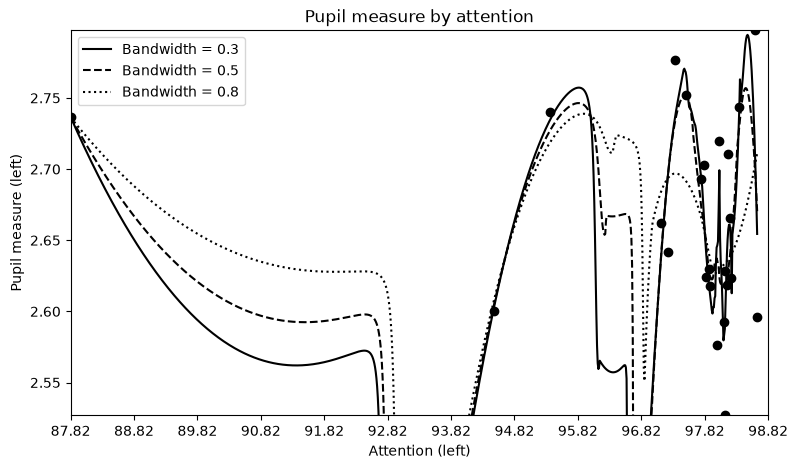

In [136]:
loess_data = panel.dropna(subset=["Attention_left", "pupil_left", "pupil_right"])

CBACABLab.CreateLOESSPlots(
    loess_data,
    xcolumn="Attention_left",
    ycolumn="pupil_left",
    bandwidths=[0.3, 0.5, 0.8],
    xlabel="Attention (left)",
    ylabel="Pupil measure (left)",
    title="Pupil measure by attention",
    xStep=1,
)

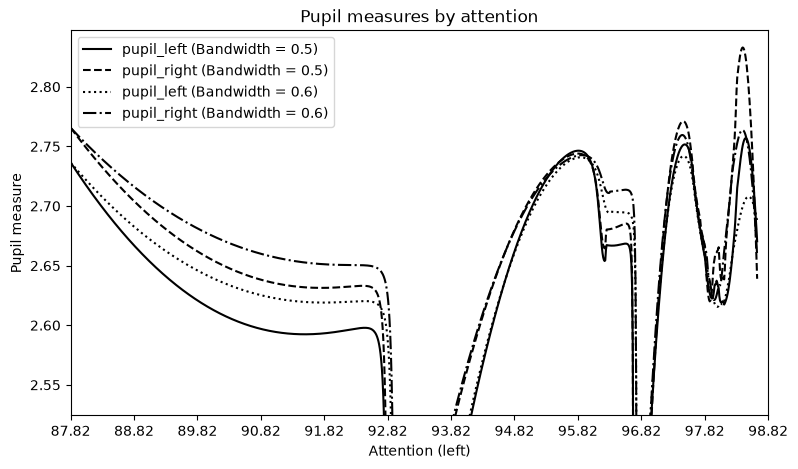

In [137]:
CBACABLab.CreateMultipleLOESSPlots(
    loess_data,
    xcolumn="Attention_left",
    ycolumns=["pupil_left", "pupil_right"],
    bandwidths=[0.5, 0.6],
    xlabel="Attention (left)",
    ylabel="Pupil measure",
    title="Pupil measures by attention",
    xStep=1,
)

## 7. Questions?

Need help with this package? Contact Ben Smith (bosmith@unomaha.edu).